# Beton Basınç Dayanımı Tahmini

Beton basınç dayanımı tahmini inşaat sektöründe yapıların dayanıklılığı ve güvenliği açısından hayati önem taşır. Doğru bir tahmin, yapıların tasarımında güvenilirlik sağlar ve yapısal mühendislik projelerinin başarılı bir şekilde tamamlanmasına katkıda bulunur. Ayrıca, seçilen veri setinin tamamen sürekli sayısal değişkenlerden oluşması, regresyon tekniklerini modellemek ve uygulamak için çok uygun bir zemin sunmaktadır.
Yapılan literatür araştırmalarının sonucunda; Lineer Regresyon, Destek Vektör Regresyonu ve Karar Ağaçları gibi çeşitli regresyon yaklaşımlarının beton basınç dayanımı tahmininde kullanıldığı görülmüştür. Veri setimizde Keşifçi Veri Analizi sonucunda elde ettiğimiz dağılım grafiklerinde 'cement' dışındaki diğer bağımsız değişkenler ile hedef değişkenimiz olan 'concrete_compressive_strength' arasında doğrusal olmayan ve karmaşık bir ilişki yapısı gözlemlenmiştir. Aynı zamanda yapılan VIF analizinde bazı değişkenler arasında çoklu doğrusallık problemi olduğu tespit edilmiştir.
Ancak bu bağımsız değişkenleri çıkarırsak modelin hedef değişkeni açıklama gücü düşeceği için hem çoklu bağlantı problemlerinden etkilenmeyen hem de doğrusal olmayan karmaşık ilişkileri yakalayabilen ağaç tabanlı modeller olan Random Forest ve XGBoost modeli tercih edilmiştir.

# 1. KÜTÜPHANELERİN YÜKLENMESİ

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from xgboost import XGBRegressor

# 2. VERİ OKUMA VE ÖN İŞLEME

In [24]:
df = pd.read_csv("concrete_data.csv")

print("\n--- VERİ SETİ ÖNİZLEME ---")
print(df.head())

print("\n--- VERİ SETİ BİLGİSİ (INFO) ---")
print(df.info())

print("\n--- İSTATİSTİKSEL ÖZET ---")
print(df.describe())

print(f"\nİlk duplicate sayısı: {df.duplicated().sum()}")
df = df.drop_duplicates()
print(f"Temizlik sonrası duplicate sayısı: {df.duplicated().sum()}")


--- VERİ SETİ ÖNİZLEME ---
   cement  blast_furnace_slag  fly_ash  water  superplasticizer  \
0   540.0                 0.0      0.0  162.0               2.5   
1   540.0                 0.0      0.0  162.0               2.5   
2   332.5               142.5      0.0  228.0               0.0   
3   332.5               142.5      0.0  228.0               0.0   
4   198.6               132.4      0.0  192.0               0.0   

   coarse_aggregate  fine_aggregate   age  concrete_compressive_strength  
0            1040.0            676.0   28                          79.99  
1            1055.0            676.0   28                          61.89  
2             932.0            594.0  270                          40.27  
3             932.0            594.0  365                          41.05  
4             978.4            825.5  360                          44.30  

--- VERİ SETİ BİLGİSİ (INFO) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data column

Text(0.5, 1.0, 'concrete_compressive_strength')

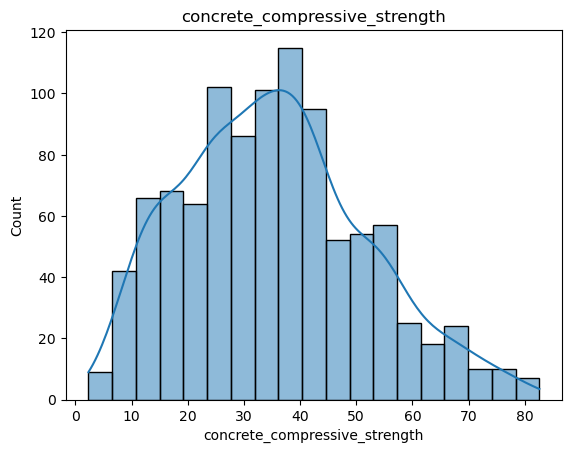

In [25]:
sns.histplot(df["concrete_compressive_strength"], kde=True)
plt.title("concrete_compressive_strength")

# 3. Keşifsel Veri Analizi (EDA)

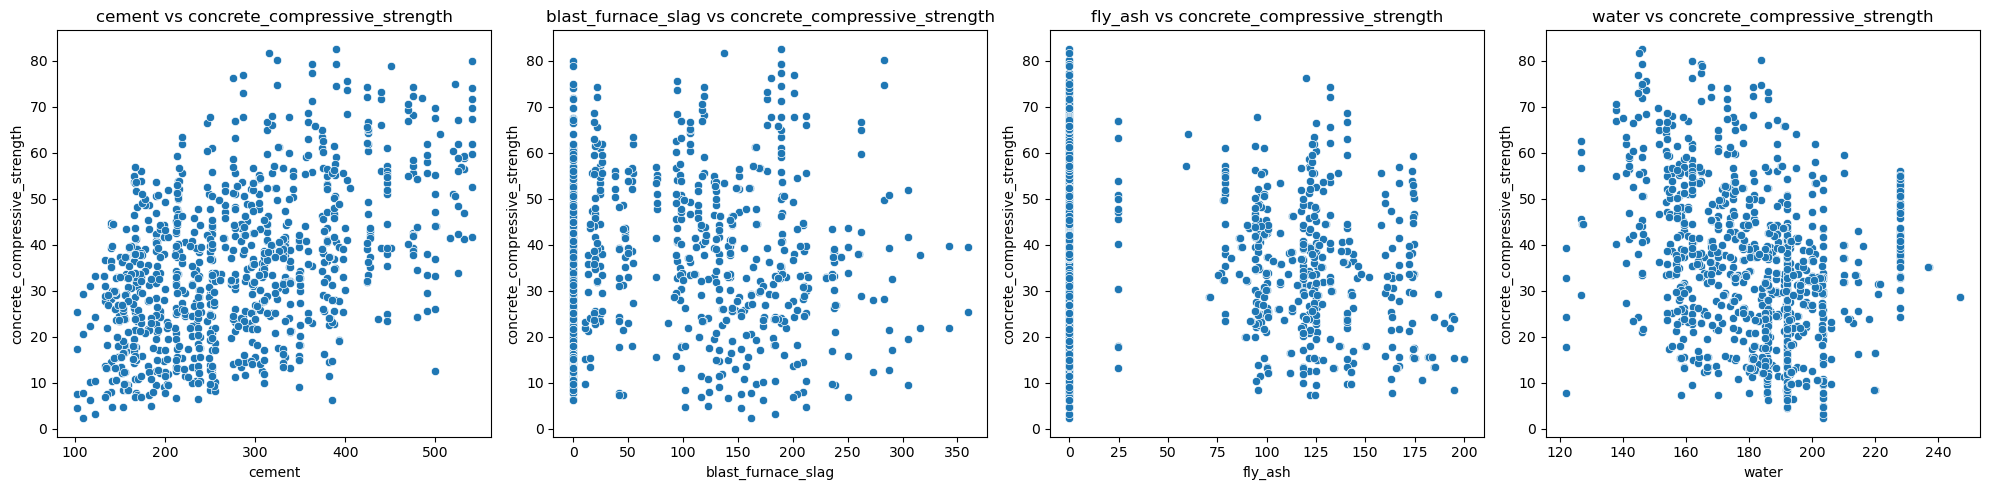

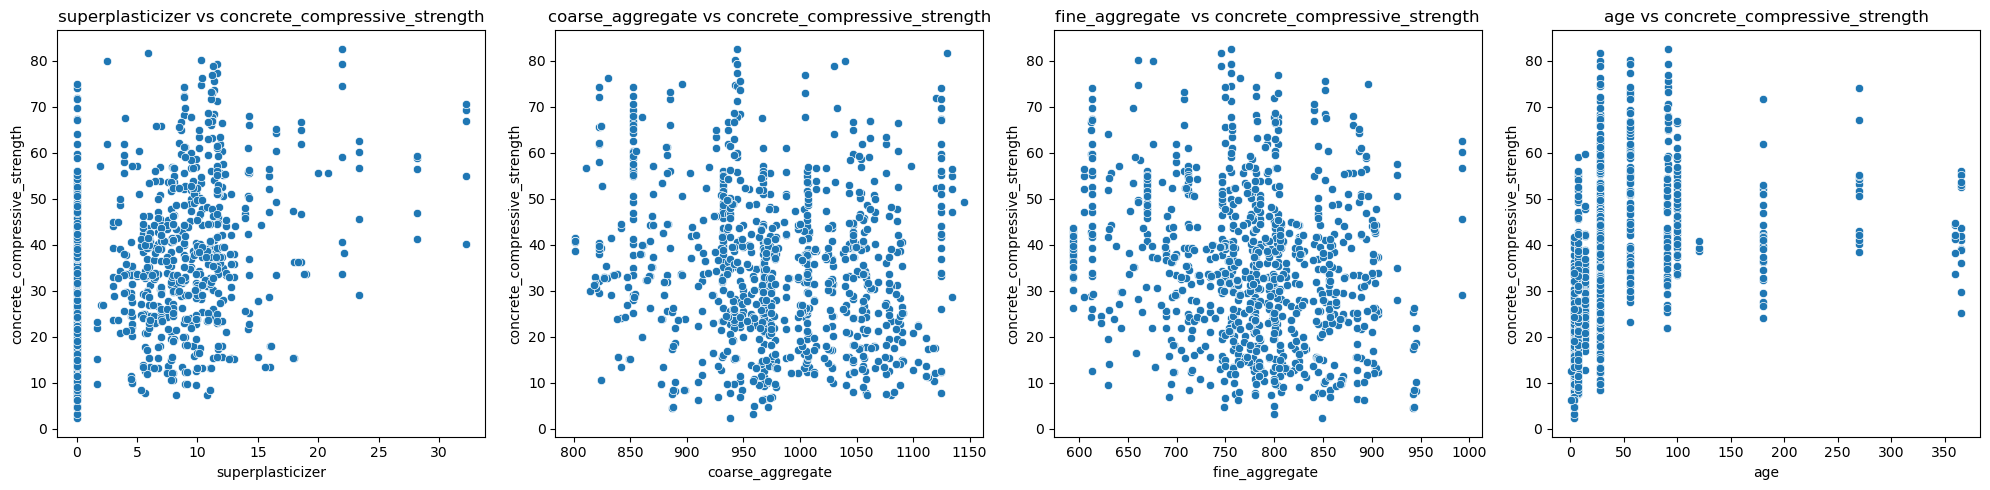

In [26]:
features = ["cement", "blast_furnace_slag", "fly_ash", "water",
            "superplasticizer", "coarse_aggregate", "fine_aggregate ", "age"]

for i in range(0, len(features), 4):
    group = features[i:i+4]
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    for ax, col in zip(axes, group):
        sns.scatterplot(x=col, y="concrete_compressive_strength", data=df, ax=ax)
        ax.set_title(f"{col} vs concrete_compressive_strength")
    plt.tight_layout()
    plt.show()

# 4. Korelasyon Analizi

In [27]:
df.corr()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
cement,1.000000,-0.303324,-0.385610,-0.056625,0.060906,-0.086205,-0.245375,0.086348,0.488283
blast_furnace_slag,-0.303324,1.000000,-0.312352,0.130262,0.019800,-0.277559,-0.289685,-0.042759,0.103374
fly_ash,-0.385610,-0.312352,1.000000,-0.283314,0.414213,-0.026468,0.090262,-0.158940,-0.080648
water,-0.056625,0.130262,-0.283314,1.000000,-0.646946,-0.212480,-0.444915,0.279284,-0.269624
superplasticizer,0.060906,0.019800,0.414213,-0.646946,1.000000,-0.241721,0.207993,-0.194076,0.344209
coarse_aggregate,-0.086205,-0.277559,-0.026468,-0.212480,-0.241721,1.000000,-0.162187,-0.005264,-0.144717
fine_aggregate,-0.245375,-0.289685,0.090262,-0.444915,0.207993,-0.162187,1.000000,-0.156572,-0.186448
age,0.086348,-0.042759,-0.158940,0.279284,-0.194076,-0.005264,-0.156572,1.000000,0.337367
concrete_compressive_strength,0.488283,0.103374,-0.080648,-0.269624,0.344209,-0.144717,-0.186448,0.337367,1.000000


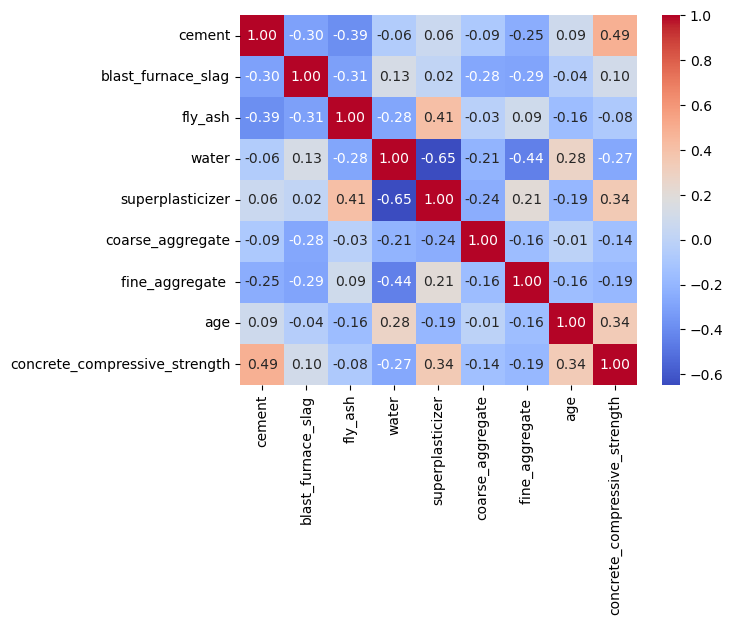

In [28]:
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm',fmt=".2f")
plt.show()

# 5. VIF Analizi

In [29]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = df[['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate ', 'age']]  

vif_df = pd.DataFrame()
vif_df['variable'] = X.columns
vif_df['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print(vif_df)

             variable        VIF
0              cement  15.143662
1  blast_furnace_slag   3.260685
2             fly_ash   4.170393
3               water  81.401338
4    superplasticizer   5.170736
5    coarse_aggregate  84.735483
6     fine_aggregate   72.490935
7                 age   1.696257


Dağılım Grafiklerinde "cement" dışındaki diğer bağımsız değişkenler ile hedef değişken "concrete_compressive_strength" arasında doğrusal
olmayan, karmaşık bir ilişki yapısı gözlemlenmiştir. Aynı zamanda yapılan VIF analizinde bazı değişkenlerde çoklu doğrusallık olduğu tespit
edilmiştir. Ancak bu bağımsız değişkenleri çıkarırsak modelin hedef değişkeni açıklama gücü düşeceği için hem çoklu bağlantı problemlerinden
etkilenmeyen hem de doğrusal olmayan karmaşık ilişkileri yakalayabilen ağaç tabanlı model olan Random Forest modeli tercih edilmiştir.

# 6. EĞİTİM VE TEST VERİLERİNİN OLUŞTURULMASI

In [30]:
X = df[['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate ', 'age']] 
y = df["concrete_compressive_strength"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\n--- TRAIN-TEST SPLIT BOYUTLARI ---")
print(f"X_train: {X_train.shape}")
print(f"X_test : {X_test.shape}")


--- TRAIN-TEST SPLIT BOYUTLARI ---
X_train: (804, 8)
X_test : (201, 8)


# 7. RANDOM FOREST MODELİ VE OPTİMİZASYONU

In [31]:
rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=rf_param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

rf_grid_search.fit(X_train, y_train)

best_rf_model = rf_grid_search.best_estimator_

print("\n--- RANDOM FOREST HİPERPARAMETRE OPTİMİZASYONU ---")
print("En İyi Parametreler:")
print(rf_grid_search.best_params_)

print(f"\n5-Fold Cross Validation Ortalama R²: {rf_grid_search.best_score_:.4f}")

Fitting 5 folds for each of 216 candidates, totalling 1080 fits

--- RANDOM FOREST HİPERPARAMETRE OPTİMİZASYONU ---
En İyi Parametreler:
{'max_depth': 20, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}

5-Fold Cross Validation Ortalama R²: 0.8845


# 8. RANDOM FOREST TRAIN VE TEST PERFORMANSI

In [32]:
# Train tahminleri ve metrikleri
rf_train_pred = best_rf_model.predict(X_train)
rf_train_mae = mean_absolute_error(y_train, rf_train_pred)
rf_train_rmse = np.sqrt(mean_squared_error(y_train, rf_train_pred))
rf_train_r2 = r2_score(y_train, rf_train_pred)

# Test tahminleri ve metrikleri
rf_test_pred = best_rf_model.predict(X_test)
rf_test_mae = mean_absolute_error(y_test, rf_test_pred)
rf_test_rmse = np.sqrt(mean_squared_error(y_test, rf_test_pred))
rf_test_r2 = r2_score(y_test, rf_test_pred)

# 9. XGBOOST MODELİ VE OPTİMİZASYONU

In [33]:
xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5, 7],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "gamma": [0, 0.1, 0.3],
    "reg_alpha": [0, 0.1],
    "reg_lambda": [1, 1.5]
}

xgb_grid_search = GridSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_grid=xgb_param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

xgb_grid_search.fit(X_train, y_train)

best_xgb_model = xgb_grid_search.best_estimator_

print("\n--- XGBOOST HİPERPARAMETRE OPTİMİZASYONU ---")
print("En İyi Parametreler:")
print(xgb_grid_search.best_params_)

print(f"\n5-Fold Cross Validation Ortalama R²: {xgb_grid_search.best_score_:.4f}")

Fitting 5 folds for each of 2916 candidates, totalling 14580 fits

--- XGBOOST HİPERPARAMETRE OPTİMİZASYONU ---
En İyi Parametreler:
{'colsample_bytree': 0.8, 'gamma': 0.3, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'reg_alpha': 0.1, 'reg_lambda': 1, 'subsample': 0.7}

5-Fold Cross Validation Ortalama R²: 0.9212


# 10. XGBOOST TRAIN VE TEST PERFORMANSI

In [34]:
# Train tahminleri ve metrikleri
xgb_train_pred = best_xgb_model.predict(X_train)
xgb_train_mae = mean_absolute_error(y_train, xgb_train_pred)
xgb_train_rmse = np.sqrt(mean_squared_error(y_train, xgb_train_pred))
xgb_train_r2 = r2_score(y_train, xgb_train_pred)

# Test tahminleri ve metrikleri
xgb_test_pred = best_xgb_model.predict(X_test)
xgb_test_mae = mean_absolute_error(y_test, xgb_test_pred)
xgb_test_rmse = np.sqrt(mean_squared_error(y_test, xgb_test_pred))
xgb_test_r2 = r2_score(y_test, xgb_test_pred)

# 11. TRAIN-TEST MODEL KARŞILAŞTIRMASI


--- DETAYLI TRAIN-TEST PERFORMANS KARŞILAŞTIRMASI ---
        Model Veri Seti       R2     RMSE      MAE
Random Forest     Train 0.983884 2.032806 1.384392
Random Forest      Test 0.905691 5.304215 3.641270
      XGBoost     Train 0.992307 1.404465 0.829369
      XGBoost      Test 0.940547 4.211441 2.757970


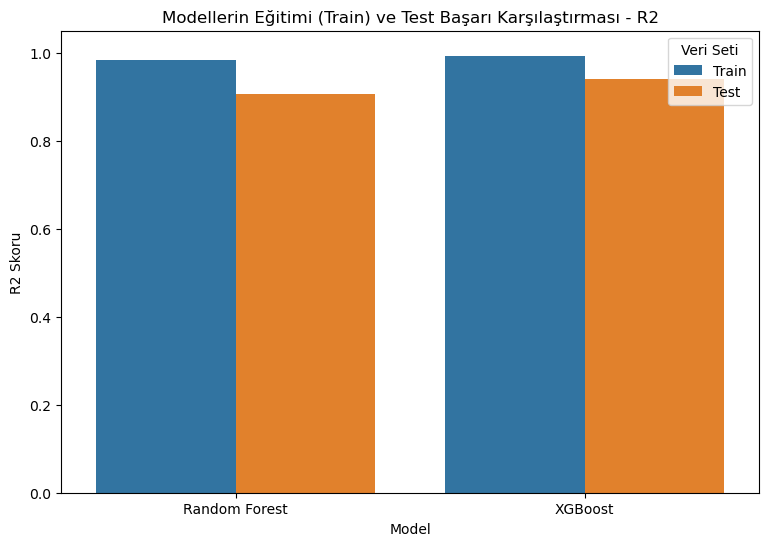

In [35]:
comparison_df = pd.DataFrame({
    "Model": ["Random Forest", "Random Forest", "XGBoost", "XGBoost"],
    "Veri Seti": ["Train", "Test", "Train", "Test"],
    "R2": [rf_train_r2, rf_test_r2, xgb_train_r2, xgb_test_r2],
    "RMSE": [rf_train_rmse, rf_test_rmse, xgb_train_rmse, xgb_test_rmse],
    "MAE": [rf_train_mae, rf_test_mae, xgb_train_mae, xgb_test_mae]
})

print("\n--- DETAYLI TRAIN-TEST PERFORMANS KARŞILAŞTIRMASI ---")
print(comparison_df.to_string(index=False))

# Grafiksel Karşılaştırma (R2 Skoru için Train vs Test)
plt.figure(figsize=(9, 6))
sns.barplot(x="Model", y="R2", hue="Veri Seti", data=comparison_df)
plt.title("Modellerin Eğitimi (Train) ve Test Başarı Karşılaştırması - R2")
plt.ylim(0, 1.05)
plt.ylabel("R2 Skoru")
plt.show()

Train ve test sonuçları karşılaştırıldığında, her iki model de train setinde çok yüksek R² değerlerine ulaşmıştır. Random Forest 0.984, XGBoost ise 0.992 değerine sahiptir. Ancak test setinde performans biraz düşmektedir. Random Forest test setinde 0.906, XGBoost ise 0.941 R² değeri vermektedir. Bu düşüş Random Forest modelinde daha belirgindir, bu yüzden Random Forest verideki gürültüyü biraz daha fazla ezberlemiş olabilir. RMSE ve MAE sonuçları da aynı durumu doğrulamaktadır. XGBoost test setinde daha düşük hata ve daha yüksek başarı göstererek Random Forest'a kıyasla daha güçlü ve daha genellenebilir bir model olarak öne çıkmaktadır.

# 12. Feature Importance

In [36]:
rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nRandom Forest Feature Importance")
print(rf_importance)


Random Forest Feature Importance
              Feature  Importance
7                 age    0.342434
0              cement    0.244317
3               water    0.115689
4    superplasticizer    0.080129
6     fine_aggregate     0.066386
1  blast_furnace_slag    0.061990
5    coarse_aggregate    0.049466
2             fly_ash    0.039590


In [37]:
xgb_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nXGBoost Feature Importance")
print(xgb_importance)


XGBoost Feature Importance
              Feature  Importance
7                 age    0.288761
0              cement    0.214741
4    superplasticizer    0.112754
3               water    0.104939
1  blast_furnace_slag    0.100615
2             fly_ash    0.071812
6     fine_aggregate     0.065802
5    coarse_aggregate    0.040576


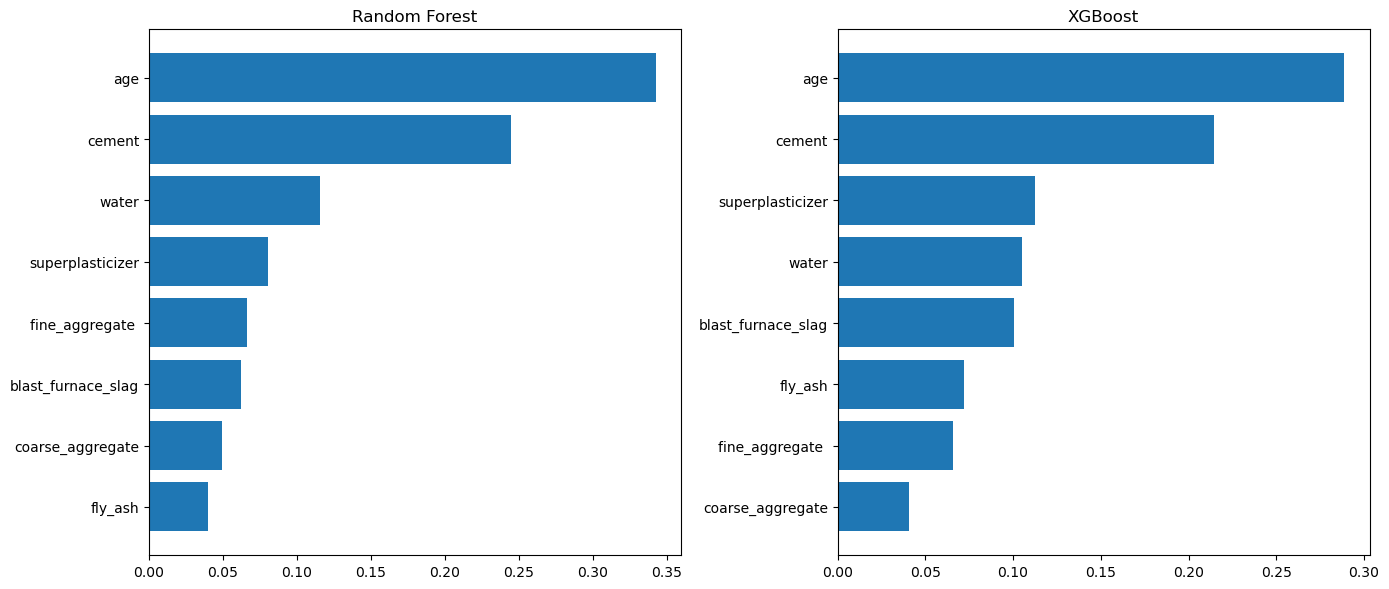

In [38]:
fig, axes = plt.subplots(1,2, figsize=(14,6))

axes[0].barh(
    rf_importance["Feature"],
    rf_importance["Importance"]
)
axes[0].invert_yaxis()
axes[0].set_title("Random Forest")

axes[1].barh(
    xgb_importance["Feature"],
    xgb_importance["Importance"]
)
axes[1].invert_yaxis()
axes[1].set_title("XGBoost")

plt.tight_layout()
plt.show()

Her iki modelde de age ve cement değişkenleri en önemli iki değişken olarak görünmektedir. İki model arasındaki tek farklılık superplasticizer değişkeninde görülmektedir; XGBoost bu değişkene Random Forest'a göre biraz daha fazla önem vermiştir. coarse_aggregate ve fly_ash ise her iki modelde de en az öneme sahip değişkenler olarak göze çarpmaktadır.

# 13. Gerçek ve Tahmin Edilen Değerler Karşılaştırması

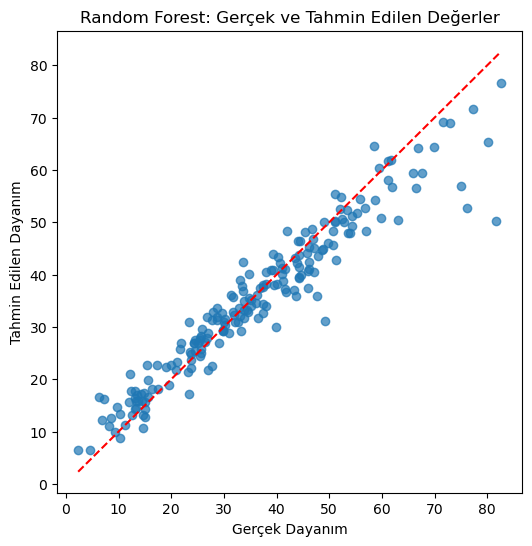

In [39]:
plt.figure(figsize=(6,6))

plt.scatter(y_test, rf_test_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Gerçek Dayanım")
plt.ylabel("Tahmin Edilen Dayanım")
plt.title("Random Forest: Gerçek ve Tahmin Edilen Değerler")

plt.show()

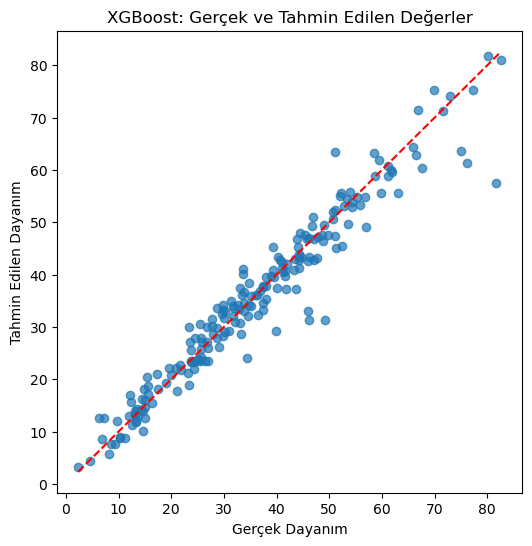

In [40]:
plt.figure(figsize=(6,6))

plt.scatter(y_test, xgb_test_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Gerçek Dayanım")
plt.ylabel("Tahmin Edilen Dayanım")
plt.title("XGBoost: Gerçek ve Tahmin Edilen Değerler")

plt.show()

Grafiklerde noktaların kırmızı çizgiye yakınlığı modelin başarısını gösterir. XGBoost modelinde noktalar çizgiye genel olarak daha yakın dağılmıştır. Random Forest modelinde ise yüksek dayanım değerlerinde gerçek değerlerden sapmalar artmaktadır. Bu durum Random Forest'ın yüksek dayanım aralığında tahmin yaparken XGBoost'a göre daha çok zorlandığını göstermektedir.

# 14. Residual Plot

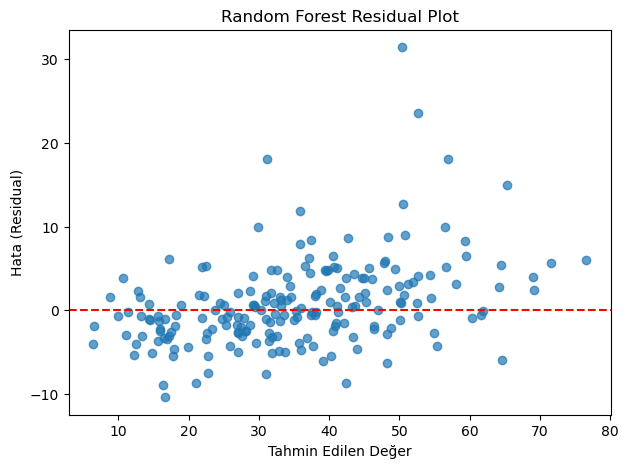

In [41]:
rf_residuals = y_test - rf_test_pred

plt.figure(figsize=(7,5))

plt.scatter(rf_test_pred, rf_residuals, alpha=0.7)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Tahmin Edilen Değer")
plt.ylabel("Hata (Residual)")
plt.title("Random Forest Residual Plot")

plt.show()

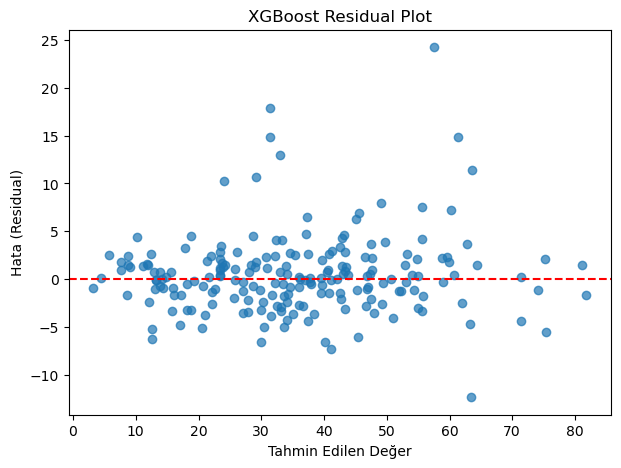

In [42]:
xgb_residuals = y_test - xgb_test_pred

plt.figure(figsize=(7,5))

plt.scatter(xgb_test_pred, xgb_residuals, alpha=0.7)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Tahmin Edilen Değer")
plt.ylabel("Hata (Residual)")
plt.title("XGBoost Residual Plot")

plt.show()

İyi bir modelde hataların sıfır çizgisi etrafında rastgele dağılması ve belirli bir düzen göstermemesi beklenir. Her iki modelin residual grafiklerinde de hatalar genel olarak sıfır etrafında toplanmış ve belirgin bir kalıp veya eğilim görülmemiştir. Bu durum, modellerin sistemli bir hata yapmadığını ve tahminlerin rastgele saçıldığını göstermektedir.

# 15 Sonuç

Bu projede beton basınç dayanımını tahmin etmek için Random Forest ve XGBoost modelleri kullanılmış ve GridSearchCV ile en iyi parametreler bulunmaya çalışılmıştır. Sonuçlara bakıldığında XGBoost modeli, hem cross validation skorunda hem de test seti üzerinde Random Forest'tan daha iyi performans göstermiştir. Random Forest da iyi bir sonuç vermiştir fakat train ve test skorları arasındaki fark, bu modelin veriye biraz daha fazla ezberleyerek uyum sağladığını göstermektedir.
Her iki modelde de age ve cement değişkenleri dayanımı en çok etkileyen değişkenler olarak öne çıkmıştır. Bu da beklenen bir sonuçtur çünkü betonun dayanımı zamanla artar ve çimento miktarı betonun gücünü doğrudan etkileyen ana bileşendir.
Sonuç olarak XGBoost modeli düşük hata oranıyla beton dayanımını başarılı bir şekilde tahmin edebilmektedir. Bu proje ile veri ön işleme, keşifsel veri analizi, çoklu doğrusallık kontrolü ve makine öğrenmesi modellerinin kurulup karşılaştırılması gibi bir regresyon probleminin uçtan uca nasıl ele alınabileceği gösterilmeye çalışılmıştır.